# Experiments

Each run trains a model from scratch and is saved in `models/<name>/`. Training uses the GPU when it is available.


- **Selection uses validation only.** Loss, embedding size and the other hyperparameters are chosen by the mean validation Hits@20.
- **Best-epoch checkpoints.** Every run keeps the weights of the epoch with the highest validation Hits@20.
- **Several seeds.** Every setting is trained once per seed (the same seeds for all settings) and reported as mean ± std, so that differences can be compared with the noise between runs.

In [1]:
!git clone https://github.com/AidaKhaleghi/Drug-Drug-Interaction_GNN.git

Cloning into 'Drug-Drug-Interaction_GNN'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 69 (delta 27), reused 58 (delta 16), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 1.85 MiB | 18.92 MiB/s, done.
Resolving deltas: 100% (27/27), done.


In [2]:
%cd Drug-Drug-Interaction_GNN
!pip install -e .
%cd src

/content/Drug-Drug-Interaction_GNN
Obtaining file:///content/Drug-Drug-Interaction_GNN
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 4.4 MB/s eta 0:00:00
  Building editable for ddi-gnn (pyproject.toml) ... done
  Created wheel for ddi-gnn: filename=ddi_gnn-0.1.0-0.editable-py3-none-any.whl size=2514 sha256=d9ae17790aae1a106665d36b4ad8fcb4da1f6373b85fe72f6dda52fe72bba7b5
  Stored in directory: /tmp/pip-ephem-wheel-cache-a1o47zwo/wheels/63/fe/5a/b9cbc227ff9c228bfc5d2769fc7692465b22192c47fd5bf8b1
Successfully built ddi-gnn
/content/Drug-Drug-Interaction_GNN/src


In [3]:
import itertools
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Markdown, display

from ddi_gnn.data import load_ddi
from ddi_gnn.experiments import (
    best_config,
    format_summary,
    load_history,
    mean_std,
    run_seeds,
    run_sweep,
    summarize_runs,
)
from ddi_gnn.plotting import plot_heatmap, plot_learning, plot_results, plot_sweep
from ddi_gnn.utils import get_device

DATA_ROOT = "/content/datasets"
SAVE_DIR = "/content/models"
RESULTS_DIR = Path("/content/Drug-Drug-Interaction_GNN/results")

# Every setting is trained once per seed (Because of computational limits, I just ran on 2 seeds but we can increase it to have more robust results)
SEEDS = [0, 1]

# Settings shared by all runs on the small dataset
RUN = dict(save_dir=SAVE_DIR, num_epochs=400, eval_every=5)

print(f"Training on: {get_device()}")

Training on: cuda


In [4]:
def show(text: str) -> None:
    """Renders text as Markdown below the cell."""
    display(Markdown(text))


def save_fig(fig, name: str) -> None:
    """Saves a figure in the results folder."""
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(RESULTS_DIR / name, dpi=150, bbox_inches="tight")

## Dataset

A random subset of 500 drugs keeps the experiments fast.

In [5]:
small_data = load_ddi(
    root=DATA_ROOT,
    node_limit=500,
    generator=torch.Generator().manual_seed(42),
)
print(f"{small_data.n_nodes} drugs, {len(small_data.splits['train'].pos)} training interactions")

Downloaded 0.04 GB: 100%|██████████| 46/46 [00:04<00:00, 11.22it/s]


Extracting /content/datasets/ddi.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 26.52it/s]

Saving...


500 drugs, 17625 training interactions


## 1. Loss function

Binary log loss (`bce`) against the AUC loss (`auc`), with the same small model.

In [6]:
BASE_MODEL = {
    "embedding_dim": 128,
    "dropout_rate": 0.3,
    "last_layer_self": False,
    "degree_norm": False,
}

loss_runs = pd.concat(
    [
        run_seeds(f"loss_{loss}", small_data, BASE_MODEL, SEEDS, loss=loss, **RUN).assign(loss=loss)
        for loss in ["bce", "auc"]
    ],
    ignore_index=True,
)
loss_summary = summarize_runs(loss_runs, ["loss"])
format_summary(loss_summary, ["loss"])

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

,loss,train,valid,best epoch
0,bce,0.753 ± 0.029,0.863 ± 0.008,392
1,auc,0.631 ± 0.032,0.879 ± 0.001,342


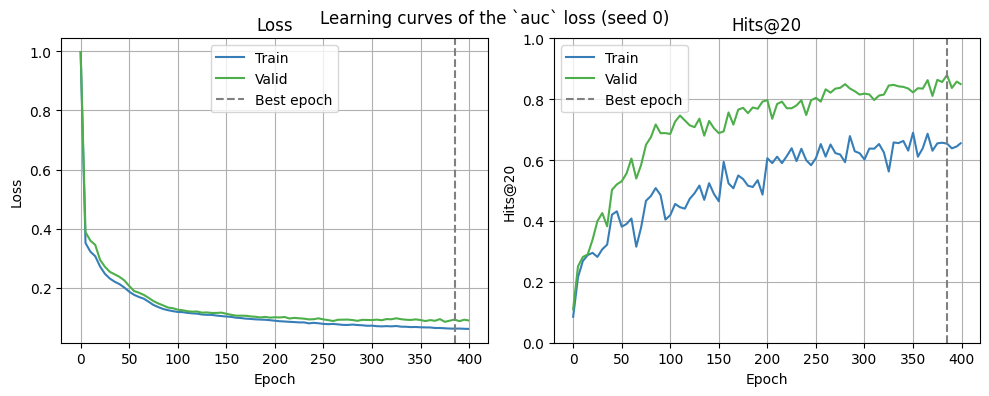

**Interpretation.** The `auc` loss reaches the higher validation Hits@20 (0.879 ± 0.001, against 0.863 ± 0.008 for `bce`). The difference of 0.016 is larger than the seed-to-seed std (0.008), so it is a reliable difference. `auc` is used in all the following experiments.

In [7]:
BEST_LOSS = best_config(loss_summary, ["loss"])["loss"]
metrics, best_epoch = load_history(SAVE_DIR, f"loss_{BEST_LOSS}/seed-{SEEDS[0]}")
fig = plot_learning(metrics, best_epoch=best_epoch)
fig.suptitle(f"Learning curves of the `{BEST_LOSS}` loss (seed {SEEDS[0]})")
save_fig(fig, "learning_curve_loss.png")
plt.show()

rows = loss_summary.set_index("loss")
other = "bce" if BEST_LOSS == "auc" else "auc"
gap = rows.loc[BEST_LOSS, "valid_mean"] - rows.loc[other, "valid_mean"]
noise = rows["valid_std"].max()
clear = gap > noise
show(
    f"**Interpretation.** The `{BEST_LOSS}` loss reaches the higher validation Hits@20 "
    f"({mean_std(rows.loc[BEST_LOSS], 'valid')}, against {mean_std(rows.loc[other], 'valid')} for `{other}`). "
    f"The difference of {gap:.3f} is {'larger than' if clear else 'within'} the seed-to-seed std ({noise:.3f}), "
    f"so it {'is a reliable difference' if clear else 'cannot be told apart from noise'}. "
    f"`{BEST_LOSS}` is used in all the following experiments."
)

## 2. Embedding dimension

In [8]:
dim_runs = run_sweep(
    "dim",
    small_data,
    BASE_MODEL,
    [{"embedding_dim": d} for d in [64, 128, 256, 512]],
    SEEDS,
    loss=BEST_LOSS,
    **RUN,
)
dim_summary = summarize_runs(dim_runs, ["embedding_dim"])
format_summary(dim_summary, ["embedding_dim"])

dim:   0%|          | 0/4 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

,embedding_dim,train,valid,best epoch
0,64,0.562 ± 0.014,0.831 ± 0.019,350
1,128,0.702 ± 0.065,0.877 ± 0.012,372
2,256,0.849 ± 0.122,0.889 ± 0.004,330
3,512,0.843 ± 0.064,0.859 ± 0.003,145


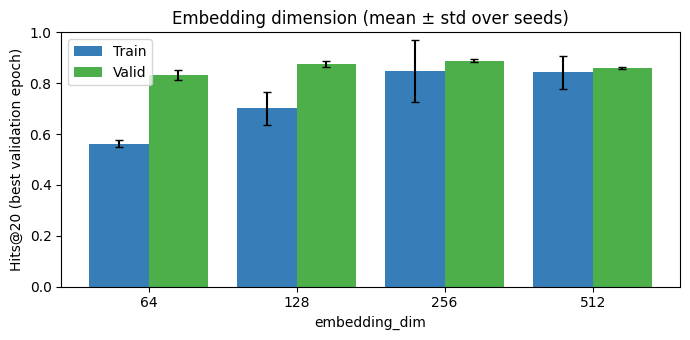

**Interpretation.** The best embedding dimension by validation is **256** (0.889 ± 0.004). The gap between train and validation Hits@20 goes from -0.27 at dimension 64 to -0.02 at dimension 512: larger embeddings memorize the training pairs and generalize worse. Dimension 256 is used from now on.

In [9]:
fig = plot_sweep(dim_summary, "embedding_dim", title="Embedding dimension (mean ± std over seeds)")
save_fig(fig, "embedding_dim.png")
plt.show()

BEST_DIM = best_config(dim_summary, ["embedding_dim"])["embedding_dim"]
dim_summary["overfit_gap"] = dim_summary["train_mean"] - dim_summary["valid_mean"]
smallest, largest = dim_summary.iloc[0], dim_summary.iloc[-1]
overfits = largest["overfit_gap"] > smallest["overfit_gap"] + 0.05
show(
    f"**Interpretation.** The best embedding dimension by validation is **{BEST_DIM}** "
    f"({mean_std(dim_summary.set_index('embedding_dim').loc[BEST_DIM], 'valid')}). "
    f"The gap between train and validation Hits@20 goes from {smallest['overfit_gap']:+.2f} "
    f"at dimension {int(smallest['embedding_dim'])} to {largest['overfit_gap']:+.2f} "
    f"at dimension {int(largest['embedding_dim'])}: "
    + (
        "larger embeddings memorize the training pairs and generalize worse."
        if overfits
        else "there is no clear sign of overfitting in this range."
    )
    + f" Dimension {BEST_DIM} is used from now on."
)

## 3. Other hyperparameters

A grid over dropout, the self-edge and degree normalization of the last convolution, and the number of predictor layers. All 36 combinations are trained with every seed.

In [10]:
sweep_grid = {
    "dropout_rate": [0.0, 0.3, 0.5],
    "last_layer_self": [True, False],
    "degree_norm": [True, False],
    "n_mlp_layers": [1, 2, 3],
}
PARAMS = list(sweep_grid)
combinations = [dict(zip(PARAMS, values)) for values in itertools.product(*sweep_grid.values())]

grid_runs = run_sweep(
    "grid",
    small_data,
    {**BASE_MODEL, "embedding_dim": BEST_DIM},
    combinations,
    SEEDS,
    loss=BEST_LOSS,
    **RUN,
)
grid_summary = summarize_runs(grid_runs, PARAMS)
top = grid_summary.sort_values("valid_mean", ascending=False).head(5)
format_summary(top, PARAMS)

grid:   0%|          | 0/36 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

...

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

,dropout_rate,last_layer_self,degree_norm,n_mlp_layers,train,valid,best epoch
35,0.5,False,False,3,0.839 ± 0.035,0.924 ± 0.006,335
29,0.5,True,False,3,0.849 ± 0.009,0.923 ± 0.006,382
26,0.5,True,True,3,0.783 ± 0.025,0.916 ± 0.002,332
28,0.5,True,False,2,0.731 ± 0.062,0.912 ± 0.007,368
31,0.5,False,True,2,0.853 ± 0.001,0.912 ± 0.015,385


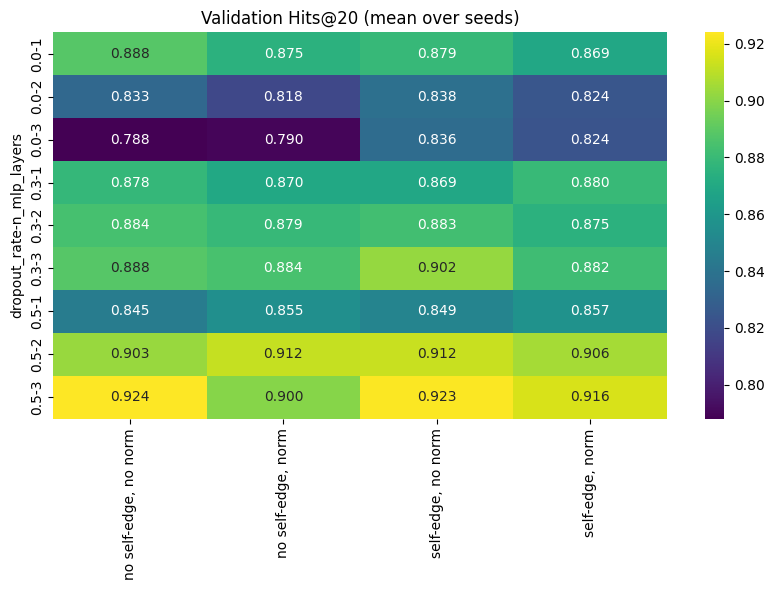

mean valid Hits@20
hyperparameter  value                    
dropout_rate    0.0                 0.839
                0.3                 0.881
                0.5                 0.892
last_layer_self 0.0                 0.867
                1.0                 0.874
degree_norm     0.0                 0.874
                1.0                 0.868
n_mlp_layers    1.0                 0.868
                2.0                 0.872
                3.0                 0.871

In [11]:
def conv_layer_label(row) -> str:
    if row["last_layer_self"] and row["degree_norm"]:
        return "self-edge, norm"
    if row["last_layer_self"]:
        return "self-edge, no norm"
    if row["degree_norm"]:
        return "no self-edge, norm"
    return "no self-edge, no norm"


grid_summary["conv_layer"] = grid_summary.apply(conv_layer_label, axis=1)
fig = plot_heatmap(
    grid_summary,
    index=["dropout_rate", "n_mlp_layers"],
    columns="conv_layer",
    title="Validation Hits@20 (mean over seeds)",
)
save_fig(fig, "grid_heatmap.png")
plt.show()

# Average validation Hits@20 for each value of each hyperparameter
marginals = pd.concat(
    {p: grid_summary.groupby(p)["valid_mean"].mean() for p in PARAMS},
    names=["hyperparameter", "value"],
)
marginals.rename("mean valid Hits@20").round(3).to_frame()

In [12]:
best_params = best_config(grid_summary, PARAMS)
BEST_MODEL = {**BASE_MODEL, "embedding_dim": BEST_DIM, **best_params}

best_row = grid_summary.set_index(PARAMS).loc[tuple(best_params.values())]
best_mean, best_std = best_row["valid_mean"], best_row["valid_std"]
n_close = int((grid_summary["valid_mean"] >= best_mean - best_std).sum())
effects = marginals.groupby(level=0).agg(lambda v: v.max() - v.min())
main_param = effects.idxmax()

show(
    f"**Interpretation.** The best setting by validation is `{best_params}` "
    f"({mean_std(best_row, 'valid')}). "
    f"{n_close} of the {len(grid_summary)} settings are within one std of it, "
    + (
        "so many settings are statistically close and the ranking among them should not be over-read. "
        if n_close > 3
        else "so the best setting stands out from the rest. "
    )
    + f"The hyperparameter with the largest average effect is `{main_param}` "
    f"(its values differ by {effects[main_param]:.3f} in mean validation Hits@20)."
)

**Interpretation.** The best setting by validation is `{'dropout_rate': 0.5, 'last_layer_self': False, 'degree_norm': False, 'n_mlp_layers': 3}` (0.924 ± 0.006). 2 of the 36 settings are within one std of it, so the best setting stands out from the rest. The hyperparameter with the largest average effect is `dropout_rate` (its values differ by 0.053 in mean validation Hits@20).

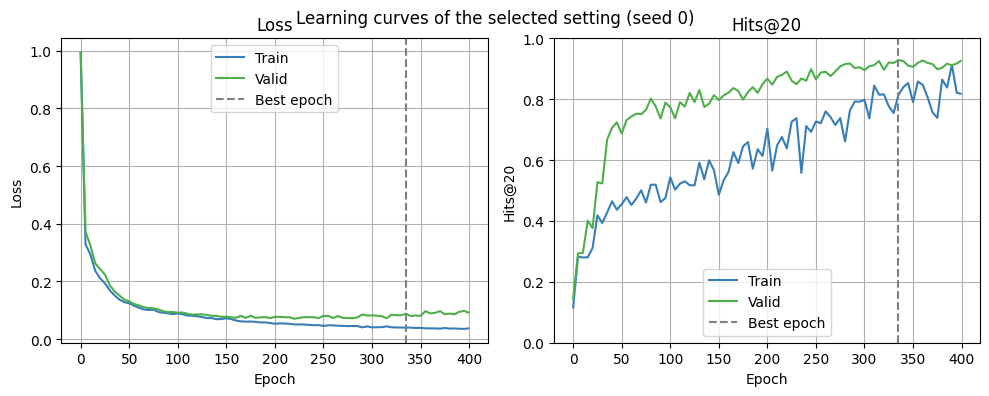

In [13]:
metrics, best_epoch = load_history(
    SAVE_DIR,
    "grid/" + "_".join(f"{k}-{v}" for k, v in best_params.items()) + f"/seed-{SEEDS[0]}",
)
fig = plot_learning(metrics, best_epoch=best_epoch)
fig.suptitle(f"Learning curves of the selected setting (seed {SEEDS[0]})")
save_fig(fig, "learning_curve_best.png")
plt.show()

## 4. Final evaluation on the test split (500 drugs)

The setting selected above is trained again with every seed, now also scoring the **test** split. This is the first and only time the test split is used to report results.

In [14]:
final_small = run_seeds(
    "final_small", small_data, BEST_MODEL, SEEDS, loss=BEST_LOSS, evaluate_test=True, **RUN
)
final_small_summary = summarize_runs(final_small, ["config"])
format_summary(final_small_summary, [])

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Training:   0%|          | 0/400 [00:00<?, ?it/s]

,train,valid,test,best epoch
0,0.819 ± 0.055,0.925 ± 0.000,0.896 ± 0.000,360


In [15]:
row = final_small_summary.iloc[0]
drop = row["valid_mean"] - row["test_mean"]
show(
    f"**Interpretation.** Test Hits@20 is {mean_std(row, 'test')}, "
    f"against {mean_std(row, 'valid')} on validation. "
    f"The test score is {abs(drop):.3f} {'below' if drop > 0 else 'above'} the validation score. "
    + (
        "A drop is expected: the setting was picked because it did well on validation, "
        "and the validation split of this small subset is small."
        if drop > 0
        else "The model does not lose performance on unseen test pairs."
    )
)

**Interpretation.** Test Hits@20 is 0.896 ± 0.000, against 0.925 ± 0.000 on validation. The test score is 0.029 below the validation score. A drop is expected: the setting was picked because it did well on validation, and the validation split of this small subset is small.

## 5. Training on a larger dataset

A random subset of 2134 drugs (half of all drugs). The setting selected on the small subset is reused **as it is**, without tuning again. Only one seed is used here because each run takes about 15 minutes. Set `LARGE_SEEDS = SEEDS` for mean ± std.

In [16]:
large_data = load_ddi(
    root=DATA_ROOT,
    node_limit=2134,
    generator=torch.Generator().manual_seed(42),
)
print(f"{large_data.n_nodes} drugs, {len(large_data.splits['train'].pos)} training interactions")
print("Model:", BEST_MODEL)

2134 drugs, 272504 training interactions
Model: {'embedding_dim': 256, 'dropout_rate': 0.5, 'last_layer_self': False, 'degree_norm': False, 'n_mlp_layers': 3}


Training:   0%|          | 0/500 [00:00<?, ?it/s]

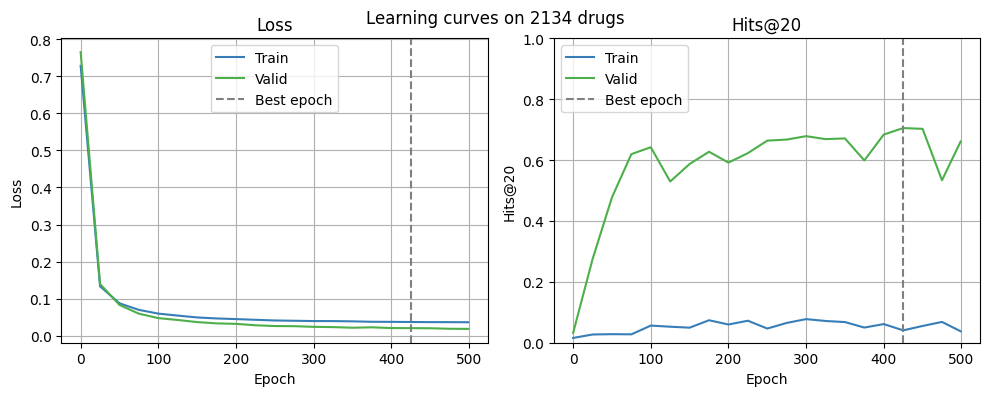

,train,valid,test,best epoch
0,0.041,0.705,0.845,425


In [17]:
LARGE_SEEDS = SEEDS[:1]

final_large = run_seeds(
    "final_large",
    large_data,
    BEST_MODEL,
    LARGE_SEEDS,
    loss=BEST_LOSS,
    save_dir=SAVE_DIR,
    num_epochs=500,
    batch_size=16384,
    eval_every=25,
    evaluate_test=True,
)
final_large_summary = summarize_runs(final_large, ["config"])

metrics, best_epoch = load_history(SAVE_DIR, f"final_large/seed-{LARGE_SEEDS[0]}")
fig = plot_learning(metrics, best_epoch=best_epoch)
fig.suptitle("Learning curves on 2134 drugs")
save_fig(fig, "learning_curve_large.png")
plt.show()
format_summary(final_large_summary, [])

In [18]:
row_small, row_large = final_small_summary.iloc[0], final_large_summary.iloc[0]
show(
    f"**Interpretation.** With the same setting, test Hits@20 is {mean_std(row_large, 'test')} "
    f"on 2134 drugs, against {mean_std(row_small, 'test')} on 500 drugs. "
    f"The best validation epoch is {int(row_large['best_epoch_mean'])} of 500"
    + (
        ", so the model was still improving when training stopped and would likely gain from more epochs."
        if row_large["best_epoch_mean"] >= 475
        else ", so validation stopped improving before the end of training."
    )
)

**Interpretation.** With the same setting, test Hits@20 is 0.845 on 2134 drugs, against 0.896 ± 0.000 on 500 drugs. The best validation epoch is 425 of 500, so validation stopped improving before the end of training.

## Summary

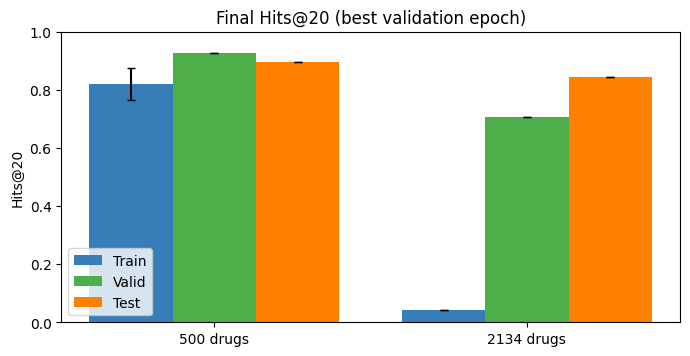

,Train Hits@20,Valid Hits@20,Test Hits@20,Best epoch,Seeds
Dataset,,,,,
500 drugs,0.819 ± 0.055,0.925 ± 0.000,0.896 ± 0.000,360,2
2134 drugs,0.041,0.705,0.845,425,1


In [19]:
datasets = {
    f"{small_data.n_nodes} drugs": (final_small_summary.iloc[0], len(SEEDS)),
    f"{large_data.n_nodes} drugs": (final_large_summary.iloc[0], len(LARGE_SEEDS)),
}
results = pd.DataFrame(
    [
        {"dataset": name, "split": split, "mean": row[f"{split}_mean"], "std": row[f"{split}_std"]}
        for name, (row, _) in datasets.items()
        for split in ("train", "valid", "test")
    ]
)

summary_table = pd.DataFrame(
    {
        name: {
            "Train Hits@20": mean_std(row, "train"),
            "Valid Hits@20": mean_std(row, "valid"),
            "Test Hits@20": mean_std(row, "test"),
            "Best epoch": int(row["best_epoch_mean"]),
            "Seeds": n_seeds,
        }
        for name, (row, n_seeds) in datasets.items()
    }
).T
summary_table.index.name = "Dataset"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
summary_table.to_csv(RESULTS_DIR / "summary.csv")
header = "| " + " | ".join([summary_table.index.name, *summary_table.columns]) + " |"
divider = "|" + "---|" * (len(summary_table.columns) + 1)
lines = [header, divider] + [
    "| " + " | ".join([str(name), *map(str, row)]) + " |" for name, row in summary_table.iterrows()
]
(RESULTS_DIR / "summary.md").write_text("\n".join(lines) + "\n")
for name, table in [("loss", loss_summary), ("embedding_dim", dim_summary), ("grid", grid_summary)]:
    table.to_csv(RESULTS_DIR / f"sweep_{name}.csv", index=False)

fig = plot_results(results)
fig.axes[0].set_title("Final Hits@20 (best validation epoch)")
save_fig(fig, "final_results.png")
plt.show()
summary_table

### Findings

In [20]:
loss_rows = loss_summary.set_index("loss")
gap_train = row_small["train_mean"] - row_small["valid_mean"]
show(
    "\n".join(
        [
            f"1. **Loss.** `{BEST_LOSS}` is the better loss on validation "
            f"({mean_std(loss_rows.loc[BEST_LOSS], 'valid')} vs {mean_std(loss_rows.loc[other], 'valid')} for `{other}`).",
            f"2. **Model size.** Embedding dimension {BEST_DIM} is the best of "
            f"{', '.join(map(str, dim_summary['embedding_dim']))}. "
            + ("Larger embeddings overfit." if overfits else "No overfitting was seen in this range."),
            f"3. **Other hyperparameters.** `{main_param}` matters most on average; "
            f"{n_close} of {len(grid_summary)} settings are within one std of the best, "
            + (
                "so the grid mostly shows which choices to avoid." if n_close > 3 else "so the winner is clear."
            ),
            f"4. **Generalization.** Test Hits@20 is {mean_std(row_small, 'test')} on 500 drugs "
            f"and {mean_std(row_large, 'test')} on 2134 drugs.",
        ]
    )
)

1. **Loss.** `auc` is the better loss on validation (0.879 ± 0.001 vs 0.863 ± 0.008 for `bce`).
2. **Model size.** Embedding dimension 256 is the best of 64, 128, 256, 512. Larger embeddings overfit.
3. **Other hyperparameters.** `dropout_rate` matters most on average; 2 of 36 settings are within one std of the best, so the winner is clear.
4. **Generalization.** Test Hits@20 is 0.896 ± 0.000 on 500 drugs and 0.845 on 2134 drugs.

In [21]:
# If you are on Colab and want to download the results, uncomment the following lines
# try:
#     from google.colab import files

#     shutil.make_archive("/content/results", "zip", RESULTS_DIR)
#     files.download("/content/results.zip")
# except ImportError:
#     pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

The experiments follow a selection-then-test protocol: every choice was made on validation Hits@20 averaged over several seeds, each run kept its best-validation checkpoint, and the test split was used only once, for the final numbers above. The figures and tables in `results/` come from this notebook.

Limits to keep in mind:

- The tuning is greedy (one hyperparameter group at a time), so interactions between the loss, the embedding size and the other settings are not explored.
- The experiments use random subsets of the drugs, fixed by one data seed. Seeds only change the model initialization and the batch order, not the data split.
- The setting selected on 500 drugs was not tuned again for 2134 drugs, and the large run uses fewer seeds. The learning rate and the number of epochs were never tuned.
- Hits@20 depends on the negative pairs of each split, so numbers are comparable within this project, not with published results on the full ogbl-ddi graph.